## 数据读取与处理

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection  import train_test_split
import xgboost as xgb
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings("ignore")
# 读入数据
raw_data= pd.read_csv('保险数据_第一期.csv')
# 缺失值(缺失值占比很少，直接删除)
df= raw_data.dropna().reset_index(drop=True)
# 分割标签
labels= df.pop("resp_flag")
# 数据类型拆分
cat_cols= df.select_dtypes(include= ["object"])   # 分类型
num_cols= df.select_dtypes(exclude= ["object"])   # 数值型
# 数据编码
encoder= OrdinalEncoder()
cat_trans= encoder.fit_transform(cat_cols)
df_cat= pd.DataFrame(cat_trans, columns= cat_cols.columns)
# 数据合并
data= pd.concat([df_cat, num_cols], axis=1)
# 分割测试集
Xtrain, Xtest, Ytrain, Ytest= train_test_split(data, labels, test_size= 0.3, stratify= labels, random_state= 42)

## 基础用法

In [2]:
# sklearn接口
from xgboost.sklearn import XGBClassifier
XGB= XGBClassifier()
XGB.fit(Xtrain, Ytrain)

print("AUC: ", roc_auc_score(Ytest, XGB.predict_proba(Xtest)[:, 1]))

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

AUC:  0.6936808292065849


In [3]:
# xgb接口，必须传入专属格式的数据
import xgboost as xgb

train= xgb.DMatrix(data= Xtrain, label= Ytrain)
XGB= xgb.train(params= {}, dtrain= train)

test= xgb.DMatrix(data= Xtest)
print(classification_report(Ytest, XGB.predict(test)>0.5))
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test)))

              precision    recall  f1-score   support

           0       0.67      0.87      0.76      7020
           1       0.65      0.36      0.46      4698

    accuracy                           0.67     11718
   macro avg       0.66      0.61      0.61     11718
weighted avg       0.66      0.67      0.64     11718

AUC:  0.6963440222486625


In [11]:
# 参数设置
param= {'max_depth': 5, 'eta': 0.4}
param['eval_metric'] = 'auc'

XGB= xgb.train(params= param, dtrain= train, evals= [(train, 'train')], num_boost_round= 15)
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test)))

[0]	train-auc:0.67738
[1]	train-auc:0.69491
[2]	train-auc:0.70464
[3]	train-auc:0.71579
[4]	train-auc:0.72262
[5]	train-auc:0.72664
[6]	train-auc:0.73052
[7]	train-auc:0.73594
[8]	train-auc:0.73903
[9]	train-auc:0.74201
[10]	train-auc:0.74513
[11]	train-auc:0.74825
[12]	train-auc:0.75240
[13]	train-auc:0.75447
[14]	train-auc:0.75749
AUC:  0.7027089935827696


In [12]:
evals=None   计算评估指标的数据集
early_stopping_rounds=None   提前停止。int。连续多少次指标没有改进，则返回上次迭代的模型

{'max_depth': 5, 'eta': 0.4, 'eval_metric': 'auc'}

In [20]:
# 提前停止
Xtrain1, Xtest1, Ytrain1, Ytest1= train_test_split(Xtrain, Ytrain, test_size= 0.3, stratify= Ytrain, random_state= 42)

train_e= xgb.DMatrix(data= Xtrain1, label= Ytrain1)
test_e= xgb.DMatrix(data= Xtest1, label= Ytest1)

# 参数设置
param= {'max_depth': 5, 'eta': 0.4}
param['eval_metric'] = 'auc'

eval_list= [(train_e, 'train_e'), (test_e, 'test_e')]   # 只有最后一个数据集用来计算early stop

XGB= xgb.train(params= param, dtrain= train_e, evals= eval_list, 
               num_boost_round= 15, early_stopping_rounds= 3)

[0]	train_e-auc:0.68374	test_e-auc:0.66808
[1]	train_e-auc:0.70596	test_e-auc:0.67730
[2]	train_e-auc:0.71695	test_e-auc:0.68206
[3]	train_e-auc:0.72557	test_e-auc:0.68365
[4]	train_e-auc:0.73287	test_e-auc:0.68694
[5]	train_e-auc:0.73984	test_e-auc:0.69110
[6]	train_e-auc:0.74474	test_e-auc:0.69322
[7]	train_e-auc:0.74958	test_e-auc:0.69315
[8]	train_e-auc:0.75358	test_e-auc:0.69289
[9]	train_e-auc:0.75738	test_e-auc:0.69327
[10]	train_e-auc:0.76147	test_e-auc:0.69397
[11]	train_e-auc:0.76353	test_e-auc:0.69409
[12]	train_e-auc:0.76674	test_e-auc:0.69572
[13]	train_e-auc:0.76963	test_e-auc:0.69556
[14]	train_e-auc:0.77338	test_e-auc:0.69582


## 进阶用法

### 单调约束

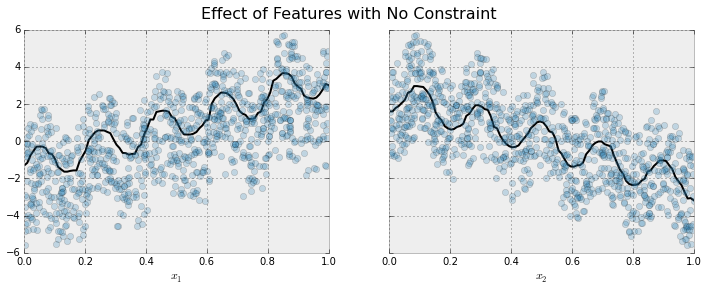

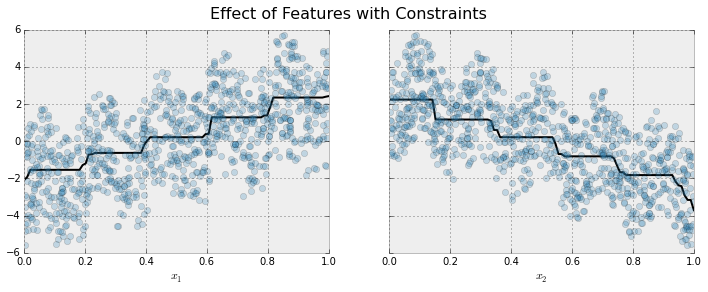

如果tree_method设置为hist或approx，启用单调约束可能会产生不必要的浅树。这是因为该hist方法减少了每次分割时要考虑的候选分割数量。单调约束可能会消除所有可用的分割候选，在这种情况下不会进行分割。为了减少这种影响，您可能需要增加max_bin参数或使用exact方法。

In [21]:
param

{'max_depth': 5, 'eta': 0.4, 'eval_metric': 'auc'}

In [22]:
# 单调约束
params_monotonic= param.copy()
params_monotonic['tree_method']= 'exact'
params_monotonic['monotone_constraints']= (0, 1, -1)   # 前三个特征分别：不设约束，单调增，单调减

XGB= xgb.train(params= params_monotonic, dtrain= train, evals= [(train, 'train')])
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test)))

[0]	train-auc:0.67740
[1]	train-auc:0.69472
[2]	train-auc:0.70512
[3]	train-auc:0.71627
[4]	train-auc:0.72202
[5]	train-auc:0.72640
[6]	train-auc:0.73103
[7]	train-auc:0.73419
[8]	train-auc:0.73872
[9]	train-auc:0.74363
AUC:  0.7012376000456035


### 交互约束

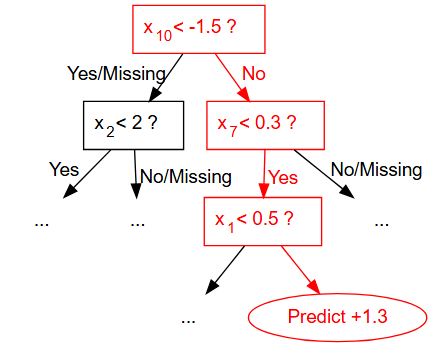

特征交互约束以允许交互的特征list来表示。例如，约束[0, 1]表示特征0和1允许相互作用，但不允许其他特征相互作用。同理，[2, 3, 4]表示特征2,3,4允许彼此交互，但不能与其他特征交互。

In [23]:
# 交互约束
params_interaction= param.copy()
params_interaction['interaction_constraints']= '[[0, 2], [1, 3, 4], [5, 6]]'

XGB= xgb.train(params= params_interaction, dtrain= train, evals= [(train, 'train')])
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test)))

[0]	train-auc:0.64042
[1]	train-auc:0.64269
[2]	train-auc:0.66382
[3]	train-auc:0.67029
[4]	train-auc:0.67066
[5]	train-auc:0.67295
[6]	train-auc:0.67558
[7]	train-auc:0.68064
[8]	train-auc:0.68454
[9]	train-auc:0.68502
AUC:  0.6691757054890304


### 基于XGBoost的随机森林（类似）

In [34]:
# 随机森林
params_rf= {
          "colsample_bynode": 0.8,   # colsample类型的参数设置任何一个即可，必须小于1
          "learning_rate": 1,   # 必须设为1
          "num_parallel_tree": 100,   # 森林中树的数量
          "subsample": 0.8,   # 必须小于1
            }

XGB= xgb.train(params= params_rf, dtrain= train, evals= [(train, 'train')], num_boost_round= 1)   # 迭代次数必须设为1，否则会生成多个森林
print("AUC: ", roc_auc_score(Ytest, XGB.predict(test)))

[0]	train-rmse:0.45263
AUC:  0.6913227305309042
